In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydhn
from pydhn.fluids import Fluid
from pydhn.soils import Soil
from pydhn.solving import SimpleStep, Scheduler

In [3]:
# ---------------------------------------------------------------------------
# Simulation parameters
# ---------------------------------------------------------------------------
STEPSIZE       = 600          # time step [s]  (10 min)
NUM_SIM_STEPS  = 1008         # 7 days × 144 steps/day
T_AMBIENT_C    = 10.0         # ambient / ground temperature [°C]

In [4]:
# ---------------------------------------------------------------------------
# File paths
# ---------------------------------------------------------------------------
PIPES_FILE = "pipes.csv"
NODES_FILE = "nodes.csv"
DEMAND_PROFILE_FILE = "../../data/demand_profile.csv"

# ---------------------------------------------------------------------------
# Load input data
# ---------------------------------------------------------------------------
pipe_data = pd.read_csv(PIPES_FILE)
node_data = pd.read_csv(NODES_FILE)
demand_profile_data = pd.read_csv(DEMAND_PROFILE_FILE)
demand_profile_data = demand_profile_data[:NUM_SIM_STEPS]

time_sim   = demand_profile_data["timestep"].values * STEPSIZE  # [s]
heat_demand = demand_profile_data["Q_W"] * (STEPSIZE / 3600)    # [Wh]
MDOT_BYPASS_KGS = 1.77 / 3600                                   # [kg/s], bypass mass flow

print(f"Loaded topological data from {PIPES_FILE} "
      f"--- dynamic simulation of {len(demand_profile_data)} time steps.")

Loaded topological data from pipes.csv --- dynamic simulation of 1008 time steps.


In [5]:
# ---------------------------------------------------------------------------
# Fluid and soil
# ---------------------------------------------------------------------------
# Properties taken from first pipe row (homogeneous network assumption)
p0 = pipe_data.iloc[0]

fluid = Fluid(
    name       = "Water",
    isconstant = True,
    cp         = p0["fluid_cp_JkgK"],
    mu         = p0["fluid_mu_Pas"],
    rho        = p0["fluid_rho_kgm3"],
    k          = p0["fluid_lambda_WmK"],
)

soil = Soil(
    k    = p0["soil_lambda_WmK"],
    temp = p0["T_ground_degC"],
)

# ---------------------------------------------------------------------------
# Built network
# ---------------------------------------------------------------------------
net = pydhn.Network()

# Add nodes
for idx, row in node_data.iterrows():
    name      = row["node_id"]
    node_type = row["node_type"]
    X, Y      = row["x_m"], row["y_m"]

    name_s = f"{name}_s"
    name_r = f"{name}_r"

    net.add_node(name=name_s, x=X, y=-Y)
    net.add_node(name=name_r, x=X, y=-Y)

    # Add substations
    if node_type == "substation":
        delta_t = float(row["delta_T_nom_K"])
        net.add_consumer(
            name              = name,
            start_node        = name_s,
            end_node          = name_r,
            control_type      = "energy",
            setpoint_type_hx  = "delta_t",
            setpoint_value_hx = -delta_t,
            design_delta_t    = abs(delta_t),
            t_out_min_hx      = 20,
            mass_flow_min     = MDOT_BYPASS_KGS,
            stepsize          = STEPSIZE,
        )

    # Add central generators
    elif node_type == "source":
        t_supply    = float(row["T_supply_set_degC"])
        p_ref       = float(row["p_pump_set_bar"])

        if idx == 0:
            setpoint_type_hyd  = "pressure"
            setpoint_value_hyd = - p_ref * 1e5

        net.add_producer(
            name                = name,
            start_node          = name_r,
            end_node            = name_s,
            setpoint_type_hyd   = setpoint_type_hyd,
            setpoint_value_hyd  = setpoint_value_hyd,
            setpoint_type_hx    = "t_out",
            setpoint_value_hx   = t_supply,
            stepsize            = STEPSIZE,
        )

# Add pipes
for _, row in pipe_data.iterrows():
    name = row["pipe_id"]
    frm  = row["from_node"]
    to   = row["to_node"]

    common = dict(
        # --- geometry ---
        diameter                = row["d_inner_m"],                 # carrier pipe inner diameter [m]
        length                  = row["length_m"],                  # pipe length [m]
        internal_pipe_thickness = row["wall_m"],                    # steel wall thickness [m]
        insulation_thickness    = row["insulation_thickness_m"],    # PUR foam thickness [m]
        casing_thickness        = row["casing_thickness_m"],        # HDPE casing wall thickness [m]
        # --- hydraulic ---
        roughness               = row["roughness_mm"],              # absolute roughness [mm]
        # --- thermal: insulation ---
        k_insulation            = row["PUR_lambda_WmK"],            # PUR thermal conductivity [W/(m·K)]
        # --- thermal: carrier pipe ---
        k_internal_pipe         = row["steel_lambda_WmK"],          # steel thermal conductivity [W/(m·K)]
        rho_wall                = row["steel_rho_kgm3"],            # steel density [kg/m³]
        cp_wall                 = row["steel_cp_JkgK"],             # steel specific heat [J/(kg·K)]
        # --- thermal: casing ---
        k_casing                = row["HDPE_lambda_WmK"],           # HDPE thermal conductivity [W/(m·K)]
        # --- burial ---
        depth                   = row["burial_depth_m"],            # burial depth [m]
        h_ext                   = row["h_ext_Wm2K"],                # external heat transfer coeff. [W/(m²·K)]
        # --- simulation ---
        stepsize                = STEPSIZE,                         # time step [s]
    )

    # Supply pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_s",
        start_node = f"{frm}_s",
        end_node   = f"{to}_s",
        line       = "supply",
        **common,
    )

    # Return pipe
    net.add_lagrangian_pipe(
        name       = f"{name}_r",
        start_node = f"{to}_r",
        end_node   = f"{frm}_r",
        line       = "return",
        **common,
    )

print("--- Network setup complete. ---")

--- Network setup complete. ---


In [6]:
# ---------------------------------------------------------------------------
# Schedules
# ---------------------------------------------------------------------------
# Consumers schedule
consumer_demand_schedule   = pd.DataFrame()
consumer_names = []

for i in node_data.index:
    row       = node_data.loc[i]
    name      = row["node_id"]
    node_type = row["node_type"]

    if node_type == "substation":
        consumer_names.append(name)

        q_wh = demand_profile_data["Q_W"] * (STEPSIZE / 3600)
        consumer_demand_schedule[name]   = -q_wh

consumer_demand_schedule   = consumer_demand_schedule[consumer_names]

schedules = {
    "heat_demand":  consumer_demand_schedule,     # [Wh]
}

print(f"Schedules built: {len(consumer_names)} consumers × {NUM_SIM_STEPS} steps.")

Schedules built: 10 consumers × 1008 steps.


In [7]:
# ---------------------------------------------------------------------------
# Pre-heating (network initialization)
# ---------------------------------------------------------------------------
print("--- Initializing Network (Pre-heating for stability) ---")

INIT_STEPS = 144  # 1 day

init_demand_consumer = pd.DataFrame(
    np.tile(consumer_demand_schedule.iloc[0].values, (INIT_STEPS, 1)),
    columns=consumer_demand_schedule.columns,
)

init_schedules = {
    "heat_demand": init_demand_consumer
}

base_loop_init = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler_init = Scheduler(
    base_loop=base_loop_init,
    schedules=init_schedules,
    steps=INIT_STEPS,
)

import time
t0 = time.perf_counter()
_  = scheduler_init.execute(net=net, fluid=fluid, soil=soil)
print(f"Pre-heating done in {time.perf_counter()-t0:.2f} s. "
      f"({INIT_STEPS} steps = {INIT_STEPS*STEPSIZE/3600:.1f} h.)")

--- Initializing Network (Pre-heating for stability) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started


C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\.venv\Lib\site-packages\pydhn\utilities\matrices.py:187: FutureWarning: incidence_matrix will return a scipy.sparse array instead of a matrix in Networkx 3.0.
  return nx.incidence_matrix(


Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop started
Loop completed
Step 26:
Loop started
Loop completed
Step 27:
Loop started
Loop completed
Step 28:
Loop started
Loop comp

In [8]:
# ---------------------------------------------------------------------------
# Full simulation
# ---------------------------------------------------------------------------
print("--- Running with Scheduler (Full Simulation) ---")

base_loop_scheduler = SimpleStep(
    hydraulic_sim_kwargs={"error_threshold": 1e-6, "verbose": False},
    thermal_sim_kwargs  ={"error_threshold": 1e-6, "verbose": False},
    with_thermal=True,
)

scheduler = Scheduler(
    base_loop=base_loop_scheduler,
    schedules=schedules,
    steps=NUM_SIM_STEPS,
)

t0 = time.perf_counter()
results = scheduler.execute(net=net, fluid=fluid, soil=soil)
sim_time = time.perf_counter() - t0

print(f"Simulation complete.")
print(f"Average simulation time: {sim_time:.2f} s.")

--- Running with Scheduler (Full Simulation) ---
Scheduler started
Step 0:
Loop started
Loop completed
Step 1:
Loop started
Loop completed
Step 2:
Loop started
Loop completed
Step 3:
Loop started
Loop completed
Step 4:
Loop started
Loop completed
Step 5:
Loop started
Loop completed
Step 6:
Loop started
Loop completed
Step 7:
Loop started
Loop completed
Step 8:
Loop started
Loop completed
Step 9:
Loop started
Loop completed
Step 10:
Loop started
Loop completed
Step 11:
Loop started
Loop completed
Step 12:
Loop started
Loop completed
Step 13:
Loop started
Loop completed
Step 14:
Loop started
Loop completed
Step 15:
Loop started
Loop completed
Step 16:
Loop started
Loop completed
Step 17:
Loop started
Loop completed
Step 18:
Loop started
Loop completed
Step 19:
Loop started
Loop completed
Step 20:
Loop started
Loop completed
Step 21:
Loop started
Loop completed
Step 22:
Loop started
Loop completed
Step 23:
Loop started
Loop completed
Step 24:
Loop started
Loop completed
Step 25:
Loop star

In [9]:
# ---------------------------------------------------------------------------
# Extracted variables
# ---------------------------------------------------------------------------
res = results.to_dataframes()

substation_names = node_data[node_data["node_type"] == "substation"]["node_id"].tolist()
source_name      = node_data[node_data["node_type"] == "source"]["node_id"].iloc[0]
pipe_names       = pipe_data["pipe_id"].tolist()

# ── ETS ──────────────────────────────────────────────────────────────────────
T_sub_s  = res["nodes"]["temperature"][[f"{n}_s" for n in substation_names]]
T_sub_r  = res["nodes"]["temperature"][[f"{n}_r" for n in substation_names]]
mdot_sub = res["edges"]["mass_flow"][substation_names]
Q_sub_W  = res["edges"]["delta_q"][substation_names] / (STEPSIZE / 3600)  # [W]
dT_sub   = pd.DataFrame(
    T_sub_s.values - T_sub_r.values,
    columns=substation_names,
)  # [K]

# ── PRODUCER ─────────────────────────────────────────────────────────────────
T_src_s  = res["nodes"]["temperature"][f"{source_name}_s"]   # supply setpoint check
T_src_r  = res["nodes"]["temperature"][f"{source_name}_r"]
mdot_src = res["edges"]["mass_flow"][source_name]
Q_src_W  = res["edges"]["delta_q"][source_name] / (STEPSIZE / 3600)  # [W]

# ── PIPE ─────────────────────────────────────────────────────────────────────
dp_pipe_s   = res["edges"]["delta_p"][[f"{n}_s"   for n in pipe_names]]   # [Pa]
dp_pipe_r   = res["edges"]["delta_p"][[f"{n}_r"   for n in pipe_names]]   # [Pa]
mdot_pipe_s = res["edges"]["mass_flow"][[f"{n}_s" for n in pipe_names]]   # [kg/s]
mdot_pipe_r = res["edges"]["mass_flow"][[f"{n}_r" for n in pipe_names]]   # [kg/s]
T_pipe_s    = res["edges"]["temperature"][[f"{n}_s" for n in pipe_names]] # [°C]
T_pipe_r    = res["edges"]["temperature"][[f"{n}_r" for n in pipe_names]] # [°C]
Q_loss_pipe_s = res["edges"]["delta_q"][[f"{n}_s" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]
Q_loss_pipe_r = res["edges"]["delta_q"][[f"{n}_r" for n in pipe_names]] / (STEPSIZE / 3600)  # [W]

# ── JUNCTION NODES ───────────────────────────────────────────────────────────
exclude_nodes = (
    {f"{n}_s" for n in substation_names} |
    {f"{n}_r" for n in substation_names} |
    {f"{source_name}_s", f"{source_name}_r"}
)
junction_cols = [c for c in res["nodes"]["temperature"].columns
                 if c not in exclude_nodes]
T_junction = res["nodes"]["temperature"][junction_cols]

# ── ENERGY BALANCE ───────────────────────────────────────────────────────────
SKIP = 144   # steps to skip (1 day initialization)

Q_prod_MWh  =  Q_src_W.iloc[SKIP:].sum() * (STEPSIZE / 3600) / 1e6
Q_cons_MWh  = -Q_sub_W.iloc[SKIP:].sum().sum() * (STEPSIZE / 3600) / 1e6
Q_loss_MWh  = -(Q_loss_pipe_s.iloc[SKIP:].sum().sum()
               + Q_loss_pipe_r.iloc[SKIP:].sum().sum()) * (STEPSIZE / 3600) / 1e6
eta_network =  Q_cons_MWh / Q_prod_MWh

print("=" * 50)
print("ENERGY BALANCE")
print("=" * 50)
print(f"  Produced:       {Q_prod_MWh:.3f} MWh")
print(f"  Consumed:       {Q_cons_MWh:.3f} MWh")
print(f"  Pipe losses:    {Q_loss_MWh:.3f} MWh")
print(f"  Network η:      {eta_network*100:.1f} %")
print("=" * 50)

# ── SOLVER ITERATIONS ────────────────────────────────────────────────────────
history = results["history"]

lengths = {k: len(v) for k, v in history.items()}
target_len = min(lengths.values())

hyd_iter   = history["hydraulics iterations"]
therm_iter = history["thermal iterations"]

if len(hyd_iter) != target_len:
    hyd_iter = hyd_iter[len(hyd_iter) - target_len:]
if len(therm_iter) != target_len:
    therm_iter = therm_iter[len(therm_iter) - target_len:]

solver_iteration_df = pd.DataFrame({
    "hydraulics_iterations": hyd_iter,
    "thermal_iterations": therm_iter,
})
solver_iteration_df.index.name = "timestep"

print("=" * 50)
print("SOLVER ITERATIONS")
print("=" * 50)
print(solver_iteration_df.describe())
print("=" * 50)

# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
import os

results_dir = os.path.join("..", "..", "results")
os.makedirs(results_dir, exist_ok=True)

output_path = os.path.join(results_dir, "DHN_THV_3G_M_S_BASE_results.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:

    # ── ETS ──────────────────────────────────────────────────────────────────
    T_sub_s.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_supply_degC")
    T_sub_r.iloc[SKIP:].to_excel(writer,  sheet_name="sub_T_return_degC")
    dT_sub.iloc[SKIP:].to_excel(writer,   sheet_name="sub_dT_K")
    mdot_sub.iloc[SKIP:].to_excel(writer, sheet_name="sub_mdot_kgs")
    Q_sub_W.iloc[SKIP:].to_excel(writer,  sheet_name="sub_Q_W")

    # ── PRODUCER ─────────────────────────────────────────────────────────────
    pd.DataFrame({
        "T_supply_degC": T_src_s.values[SKIP:],
        "T_return_degC": T_src_r.values[SKIP:],
        "mdot_kgs":      mdot_src.values[SKIP:],
        "Q_W":           Q_src_W.values[SKIP:],
    }).to_excel(writer, sheet_name="source")

    # ── PIPE ─────────────────────────────────────────────────────────────────
    dp_pipe_s.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_s_dp_Pa")
    dp_pipe_r.iloc[SKIP:].to_excel(writer,       sheet_name="pipe_r_dp_Pa")
    mdot_pipe_s.iloc[SKIP:].to_excel(writer,     sheet_name="pipe_s_mdot_kgs")
    T_pipe_s.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_s_T_out_degC")
    T_pipe_r.iloc[SKIP:].to_excel(writer,        sheet_name="pipe_r_T_out_degC")
    Q_loss_pipe_s.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_s_Qloss_W")
    Q_loss_pipe_r.iloc[SKIP:].to_excel(writer,   sheet_name="pipe_r_Qloss_W")

    # ── JUNCTION NODES ───────────────────────────────────────────────────────
    T_junction.iloc[SKIP:].to_excel(writer, sheet_name="junction_T_degC")

    # ── ENERGY BALANCE ───────────────────────────────────────────────────────
    pd.DataFrame({
        "Q_produced_MWh": [Q_prod_MWh],
        "Q_consumed_MWh": [Q_cons_MWh],
        "Q_losses_MWh":   [Q_loss_MWh],
        "eta_network":    [eta_network],
    }).to_excel(writer, sheet_name="energy_balance")

    # ── SOLVER ITERATIONS ────────────────────────────────────────────────────
    solver_iteration_df.iloc[SKIP:].to_excel(writer, sheet_name="solver_iteration")

print(f"Results saved in: {os.path.abspath(output_path)}")

ENERGY BALANCE
  Produced:       18.257 MWh
  Consumed:       10.050 MWh
  Pipe losses:    8.227 MWh
  Network η:      55.0 %
SOLVER ITERATIONS
       hydraulics_iterations  thermal_iterations
count            1008.000000         1008.000000
mean                3.881944            1.190476
std                16.853035            0.612213
min                 0.000000            1.000000
25%                 0.000000            1.000000
50%                 0.000000            1.000000
75%                 0.000000            1.000000
max               100.000000            4.000000
Results saved in: C:\Users\sara.ferrero\PycharmProjects\dhn-benchmark\archetypes_generation\results\DHN_THV_3G_M_S_BASE_results.xlsx


In [29]:
# ── SOLVER ITERATIONS & CONVERGENCE DIAGNOSTICS ─────────────────────────────
lengths = {k: len(v) for k, v in history.items()}
target_len = min(lengths.values())

def _align(v, target_len):
    return v[len(v) - target_len:] if len(v) != target_len else v

hyd_iter     = _align(history["hydraulics iterations"], target_len)
therm_iter   = _align(history["thermal iterations"], target_len)
hyd_conv     = _align(history["hydraulics converged"], target_len)
therm_conv   = _align(history["thermal converged"], target_len)
hyd_errors_raw = _align(history["hydraulics errors"], target_len)

hyd_errors = [e if isinstance(e, list) else [e] for e in hyd_errors_raw]

final_residual = [e[-1] for e in hyd_errors]

oscillation_amplitude = [
    (max(e[-20:]) - min(e[-20:])) if len(e) >= 20 else (max(e) - min(e))
    for e in hyd_errors
]

solver_iteration_df = pd.DataFrame({
    "hydraulics_iterations":    hyd_iter,
    "hydraulics_converged":     hyd_conv,
    "final_residual":           final_residual,
    "oscillation_amplitude":    oscillation_amplitude,
    "thermal_iterations":       therm_iter,
    "thermal_converged":        therm_conv,
})
solver_iteration_df.index.name = "timestep"

Q_demand_tot_full = (heat_demand  / (STEPSIZE / 3600)).values
Q_demand_tot_aligned = _align(list(Q_demand_tot_full), target_len)
solver_iteration_df["Q_demand_tot_W"] = Q_demand_tot_aligned

print("=" * 50)
print("SOLVER ITERATIONS & CONVERGENCE")
print("=" * 50)
print(solver_iteration_df.describe())
n_fail_hyd = (~solver_iteration_df["hydraulics_converged"].astype(bool)).sum()
n_fail_therm = (~solver_iteration_df["thermal_converged"].astype(bool)).sum()
print(f"\nTimestep hydraulics NOT convergent: {n_fail_hyd}/{len(solver_iteration_df)} "
      f"({100*n_fail_hyd/len(solver_iteration_df):.2f}%)")
print(f"Timestep thermal NOT convergent:    {n_fail_therm}/{len(solver_iteration_df)} "
      f"({100*n_fail_therm/len(solver_iteration_df):.2f}%)")
print("=" * 50)

SOLVER ITERATIONS & CONVERGENCE
       hydraulics_iterations  final_residual  oscillation_amplitude  \
count            1008.000000    1.008000e+03            1008.000000   
mean                3.881944    5.645535e-02              37.252140   
std                16.853035    3.496571e-01             210.758167   
min                 0.000000    3.109663e-07               0.000000   
25%                 0.000000    6.776103e-07               0.000000   
50%                 0.000000    7.001845e-07               0.000000   
75%                 0.000000    7.001846e-07               0.000000   
max               100.000000    2.678831e+00            1847.250490   

       thermal_iterations  Q_demand_tot_W  
count         1008.000000     1008.000000  
mean             1.190476    44084.201389  
std              0.612213    35962.819183  
min              1.000000        0.000000  
25%              1.000000        0.000000  
50%              1.000000    61250.000000  
75%              1.0

In [30]:
oscillation_amplitude_fixed = [
    (max(e[-20:]) - min(e[-20:])) if len(e) >= 20 else np.nan
    for e in hyd_errors
]
solver_iteration_df["oscillation_amplitude"] = oscillation_amplitude_fixed

print(solver_iteration_df.loc[~solver_iteration_df["hydraulics_converged"].astype(bool),
                                ["hydraulics_iterations", "final_residual", "oscillation_amplitude"]])

          hydraulics_iterations  final_residual  oscillation_amplitude
timestep                                                              
38                          100        1.176338               6.284612
40                          100        1.717509               1.458113
44                          100        2.678831               2.794843
45                          100        2.556795               0.709628
182                         100        1.176338               6.284612
184                         100        1.717509               1.458113
188                         100        2.678831               2.794843
189                         100        2.556795               0.709628
326                         100        1.176338               6.284612
328                         100        1.717509               1.458113
332                         100        2.678831               2.794843
333                         100        2.556795               0.709628
470   

Diagnostic plot saved: ..\..\results\DHN_THV_3G_M_S_BASE_convergence_diagnostic.png


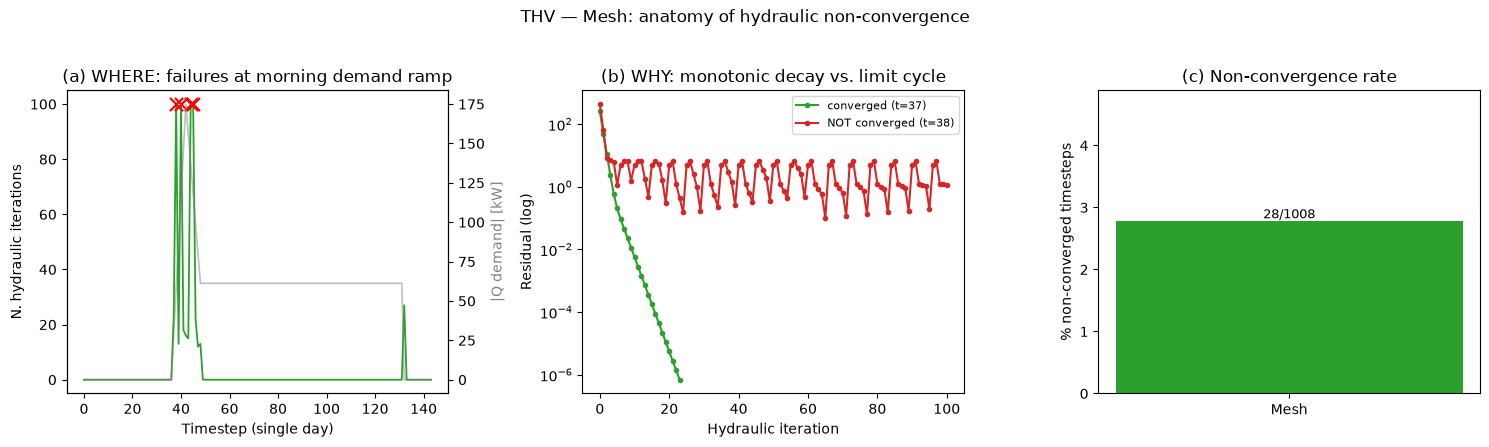

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# (a) WHERE
ax = axes[0]
day = solver_iteration_df.iloc[0:144]
ax2 = ax.twinx()
ax2.plot(day.index, day["Q_demand_tot_W"].abs()/1e3, color="gray", alpha=0.5, linewidth=1.2)
ax2.set_ylabel("|Q demand| [kW]", color="gray")
ax.plot(day.index, day["hydraulics_iterations"], color="tab:green", linewidth=1.3)
fail_day = day[~day["hydraulics_converged"].astype(bool)]
ax.scatter(fail_day.index, fail_day["hydraulics_iterations"], color="red", marker="x", s=90, zorder=5)
ax.set_xlabel("Timestep (single day)")
ax.set_ylabel("N. hydraulic iterations")
ax.set_title("(a) WHERE: failures at morning demand ramp")

# (b) WHY
ax = axes[1]
fail_idx_list = solver_iteration_df.index[~solver_iteration_df["hydraulics_converged"].astype(bool)]
normal_idx_list = solver_iteration_df.index[
    (solver_iteration_df["hydraulics_converged"]) & (solver_iteration_df["hydraulics_iterations"] > 5)
]

if len(fail_idx_list) > 0 and len(normal_idx_list) > 0:
    normal_idx = normal_idx_list[0]
    fail_idx_example = fail_idx_list[0]
    ax.plot(hyd_errors[normal_idx], color="tab:green", marker="o", markersize=3,
            label=f"converged (t={normal_idx})")
    ax.plot(hyd_errors[fail_idx_example], color="tab:red", marker="o", markersize=3,
            label=f"NOT converged (t={fail_idx_example})")
ax.set_yscale("log")
ax.set_xlabel("Hydraulic iteration")
ax.set_ylabel("Residual (log)")
ax.set_title("(b) WHY: monotonic decay vs. limit cycle")
ax.legend(fontsize=8)

# (c) HOW MUCH
ax = axes[2]
n_fail = (~solver_iteration_df["hydraulics_converged"].astype(bool)).sum()
pct_fail = 100 * n_fail / len(solver_iteration_df)
ax.bar(["Mesh"], [pct_fail], color="tab:green")
ax.annotate(f"{n_fail}/{len(solver_iteration_df)}", (0, pct_fail), ha="center", va="bottom", fontsize=9)
ax.set_ylabel("% non-converged timesteps")
ax.set_title("(c) Non-convergence rate")
ax.set_ylim(0, pct_fail * 1.4 + 1)

fig.suptitle("THV — Mesh: anatomy of hydraulic non-convergence", y=1.03)
plt.tight_layout()

fig_path = os.path.join(results_dir, "DHN_THV_3G_M_S_BASE_convergence_diagnostic.png")
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Diagnostic plot saved: {fig_path}")
plt.show()